# 새로 등록한 게임의 그림체 기본 설정 확인 (C·B 그림, 11/03)

서비스 이용자는 자기 게임을 등록할 때 레퍼런스 아트(필요하면 LoRA)만 올린다. 예시 게임 3개는 07·12에서 게임마다 그림체 태그·IP-Adapter 방식·장면 가중치를 실험으로 정했지만, 새로 등록한 게임에는 그런 태그가 없다. 그래서 게임 태그 없이 레퍼런스 아트와 IP-Adapter만으로 그리는 기본 설정이 게임별로 정한 설정과 비교해 그림체·장면을 얼마나 유지하는지 예시 게임 3개로 확인한다.

| 조건 | 프롬프트 | 부정 프롬프트 | IP-Adapter |
|---|---|---|---|
| 정한 설정 (12 IP-Adapter 켬) | 게임별 (냥기사 캐릭터 태그 / KayKit low poly / 0x72 장면 가중치) | 게임별 + `nsfw` | 게임별 (냥기사·0x72 전체 층 0.5, KayKit 그림체 블록) |
| 기본 설정 (이번에 생성) | `safe, 장면, 품질 태그` | 기본 부정 + `nsfw` | 전체 층 0.5 |

- 기본 설정 근거: rating 태그 `safe`/`nsfw`는 07 "F2"·10/26 결정, 품질 태그·부정 프롬프트는 07 "설정"(Animagine XL 4.0 모델 카드), IP-Adapter 전체 층은 05·10/26 결정의 기본 방식, 강도 0.5는 05에서 냥기사·0x72의 그림체 점수가 가장 높았던 값이다(KayKit은 0.8). 새 게임은 05처럼 강도를 고를 기록이 없어 하나로 둔다.
- 입력: 12와 같은 장면 18건(게임마다 6건, 07 R2에서 Qwen이 한국어 요청을 바꾼 영어 장면 태그), 같은 참조 이미지, seed 0·1. 생성 설정도 12와 같다(animagine-xl-4.0, Euler Ancestral 28스텝, CFG 5, 1216×832, bf16).
- 정한 설정 쪽은 다시 만들지 않고 12 결과 이미지(`outputs/promo_c/C_*_ipa_s*.png`)를 그대로 쓴다. 지표는 두 조건 모두 이 노트북에서 같은 기준으로 다시 재고, 12 `c_scored.csv` 값과 같은지 확인한다.
- 지표: 12 "지표" 셀과 같다(`style_sim` 게임 원본 100장과의 CLIP 평균 유사도, `scene_sim` 장면 태그 문장과의 CLIP 유사도, `two_cat_prob`·`exposed_prob` CLIP 제로샷, 그림으로 함께 확인).
- 냥기사 LoRA(18)는 넣지 않는다. 두 조건 모두 LoRA 없이 프롬프트·IP-Adapter 설정만 다르게 해 비교한다.
- 기록 (`outputs/promo_c_default/`): `cd_config.json`, `cd_records.csv`, `cd_runs.csv`, `cd_scored.csv`, `cd_summary.csv`, `cd_scores.png`, `cd_grid_{nai,kaykit,x72}.png`
- 진행 출력: 생성은 별도 프로세스에서 하고, 모델 로드 시작·끝과 장마다 `[시각 | 경과 | VRAM] i/전체`를 바로 출력한다.
- 예상 시간: 36장 × 장당 약 10초(12 기록 9.8~10.2초) + 모델 로드 17.5초(12) → 약 7분.
- GPU를 다른 노트북(21 등)과 동시에 쓰지 않는다.

## 설정 (12 "설정" 셀과 같음 + 기본 설정)

In [1]:
import gc
import importlib.metadata
import json
import os
import platform
import re
import subprocess
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

ROOT = Path('..')
RAW = ROOT / 'data' / 'raw'
FIX_DIR = ROOT / 'outputs' / 'banner_fix'
C12_DIR = ROOT / 'outputs' / 'promo_c'
OUT_DIR = ROOT / 'outputs' / 'promo_c_default'
OUT_DIR.mkdir(parents=True, exist_ok=True)
REC_CSV = OUT_DIR / 'cd_records.csv'
RUNS_CSV = OUT_DIR / 'cd_runs.csv'

# 07 "설정"과 같은 모델·IP-Adapter·참조 이미지·태그
MODEL = 'cagliostrolab/animagine-xl-4.0'
IPA = dict(repo='h94/IP-Adapter', subfolder='sdxl_models', weight_name='ip-adapter_sdxl.bin')
REFS = {'nai': RAW / 'nai' / 'lora_gen' / 'gen_0053_protagonist.png',
        'kaykit': RAW / 'kaykit' / 'renders' / 'kk_0185.png',
        'x72': RAW / 'pixel_0x72' / 'scenes' / 'x72_scene_0454.png'}
GAME_TAGS = {
    'nai': ('no humans, black cat adventurer, yellow eyes, red wide-brim hat, ears through headwear, olive green capelet, '
            'brown cross-shaped clasp, brown belt, short sword at hip, olive green cape with shield emblem, '
            'flat color, cel shading, clean thin lineart, soft bright colors, storybook fantasy, anime style'),
    'kaykit': 'low poly 3d game character render, knight',
    'x72': 'pixel art, 16-bit dungeon',
}
QUALITY = 'masterpiece, high score, great score, absurdres'
NEGATIVE = 'text, letters, words, watermark, signature, logo, lowres, worst quality, bad quality'
W, H = 1216, 832
STEPS, CFG = 28, 5.0
SEEDS = [0, 1]

# 07 "배너 문제 수정 실험" 설정과 같은 값
STYLE_ONLY = {'up': {'block_0': [0.0, 1.0, 0.0]}}
NAI_SHORT = 'no humans, black cat adventurer, yellow eyes, red wide-brim hat, olive green capelet, olive green cape with shield emblem'
ipa_sum = pd.read_csv(ROOT / 'outputs' / 'ipa_compare' / 'ipa_gen_summary.csv', encoding='utf-8-sig')
ipa_sum = ipa_sum[ipa_sum.model == 'animagine_xl4']
SCALE = ipa_sum.loc[ipa_sum.groupby('game').style_sim.idxmax()].set_index('game').scale.to_dict()
print('게임별 전체 층 강도(05 style_sim 최대):', SCALE)

# 10/26 결정: 게임별 프롬프트·IP-Adapter, rating 태그(긍정 safe, 부정 nsfw)
GAME_CFG = {
    'nai': dict(prompt=lambda s: f'{NAI_SHORT}, safe, {s}, {QUALITY}', negative=NEGATIVE + ', nsfw',
                ipa=SCALE['nai'], ipa_name='all_layers', compel=False),
    'kaykit': dict(prompt=lambda s: f"3d, low poly, render, {GAME_TAGS['kaykit']}, safe, {s}, {QUALITY}",
                   negative=NEGATIVE + ', anime, 1girl, nsfw', ipa=STYLE_ONLY, ipa_name='style_only', compel=False),
    'x72': dict(prompt=lambda s: f"{GAME_TAGS['x72']}, safe, ({s})1.3, {QUALITY}", negative=NEGATIVE + ', nsfw',
                ipa=SCALE['x72'], ipa_name='all_layers', compel=True),
}
# 07 F와 같은 프롬프트인지 확인 (F의 safe 조건 기록과 비교)
_f = pd.read_csv(FIX_DIR / 'final_records.csv', keep_default_na=False)
_f = _f[_f.rating == 'safe']
_f_name = {'nai': ('nai_short_tags', 'all_layers'), 'kaykit': ('kaykit_lowpoly_neg', 'style_only'),
           'x72': ('x72_compel_weight', 'all_layers')}
_req1 = pd.read_csv(ROOT / 'outputs' / 'banner_request' / 'request_records.csv').set_index('item')
for g, (n, m) in _f_name.items():
    r = _f[(_f['name'] == n) & (_f['mode'] == m)].iloc[0]
    assert GAME_CFG[g]['prompt'](_req1.loc[r['item'], 'scene']) == r.prompt and GAME_CFG[g]['negative'] == r.negative, g
print('07 F safe 조건과 프롬프트·부정 프롬프트 같음')

# 입력 장면: 07 R2의 Qwen 결과(current, seed 0)에서 장면 태그를 꺼냄
r2 = pd.read_csv(FIX_DIR / 'promo_fix_records.csv', keep_default_na=False)
r2 = r2[(r2.method == 'current') & (r2.seed == 0)]


def scene_of(raw):
    m = re.search(r'\{.*\}', raw, re.S)
    return json.loads(m.group(0))['scene']


SCENES = pd.DataFrame(dict(item=r2['item'], game=r2.game, request=r2.request, scene=r2.raw.map(scene_of))).reset_index(drop=True)
assert len(SCENES) == 18 and SCENES.scene.str.len().gt(0).all()
assert SCENES.game.value_counts().eq(6).all()
pd.set_option('display.max_colwidth', 120)
display(SCENES)


# 새로 등록한 게임의 기본 설정: 게임 태그 없음, rating 태그(07 F2), 품질 태그·부정 프롬프트(07), IP-Adapter 전체 층 0.5(05)
DEFAULT = dict(prompt=lambda sc: f'safe, {sc}, {QUALITY}', negative=NEGATIVE + ', nsfw', ipa=0.5, ipa_name='all_layers', compel=False)
# 12 정한 설정(IP-Adapter 켬) 기록: 같은 장면·seed인지 확인
c12 = pd.read_csv(C12_DIR / 'c_scored.csv', keep_default_na=False)
c12 = c12[c12.use_ipa.astype(str) == 'True'].reset_index(drop=True)
assert set(zip(c12['item'], c12.seed.astype(int))) == {(it, s_) for it in SCENES['item'] for s_ in SEEDS}, '12 기록의 장면·seed가 다름'
assert all((C12_DIR / f).exists() for f in c12.file), '12 이미지 없음'
print('12 정한 설정 이미지', len(c12), '장 | 기본 설정 예시 (냥기사 첫 장면):', DEFAULT['prompt'](SCENES.scene[0]))

게임별 전체 층 강도(05 style_sim 최대): {'kaykit': 0.8, 'nai': 0.5, 'x72': 0.5}
07 F safe 조건과 프롬프트·부정 프롬프트 같음


,item,game,request,scene
0,B0,nai,여름 바다 배경으로 냥기사 할인 배너 만들어줘. 50% 할인이고 10월 25일부터 11월 3일까지야.,"summer beach, sunset, waves, palm trees, sandy shore, horizon, blue sky, gentle breeze"
1,B1,nai,"할로윈 분위기로 밤 숲에서 이벤트 배너, 신규 의상 업데이트 알려줘","moonlit forest, glowing pumpkins, misty path, autumn leaves, black cat knight, eerie trees"
2,B2,kaykit,"성 앞마당에서 기사가 깃발 든 느낌으로 신규 영웅 업데이트 배너, 버전 1.2, 11월 1일 출시","castle courtyard, knight standing, flag waving, medieval fantasy, open plaza, stone architecture"
3,B3,kaykit,"눈 내리는 겨울 마을 배경으로 겨울 이벤트 배너 만들어줘, 30% 할인","snowy village, winter trees, glowing lanterns, frozen river, cozy cabin, soft snowfall"
4,B4,x72,"금화가 가득한 보물방 배경으로 던전 확장팩 출시 기념 30% 할인 배너, 11월 5일까지","pixel dungeon, treasure room, gold coins, glowing artifacts, ancient stone walls, torchlight, map scroll, locked che..."
5,B5,x72,용암 던전 배경으로 보스 레이드 이벤트 배너 만들어줘,"lava dungeon, pixel art, fiery cavern, glowing magma, dungeon corridor, boss fight, dark stone walls, pixelated torc..."
6,B6,nai,벚꽃 핀 봄 언덕에서 냥기사 신규 스킨 공개 배너 만들어줘,"spring_hill, cherry_blossom, soft_light, gentle_wind, cat_knight, peaceful_landscape"
7,B7,nai,"눈 오는 크리스마스 마을 배경으로 냥기사 겨울 업데이트 배너, 12월 20일 업데이트","snowy village, christmas lights, cat knight, winter landscape, frozen trees, cozy rooftops"
8,B8,nai,"바다 위 배에서 냥기사 해적 의상 20% 할인 배너, 이번 주말까지","ship at sea, black cat knight, stormy ocean, wooden deck, pirate hat, sword in hand"
9,B9,nai,도서관 배경으로 냥기사 스토리 2장 공개 배너,"library, bookshelves, candlelight, parchment, wooden floor, old windows, quiet atmosphere, fantasy setting"


12 정한 설정 이미지 36 장 | 기본 설정 예시 (냥기사 첫 장면): safe, summer beach, sunset, waves, palm trees, sandy shore, horizon, blue sky, gentle breeze, masterpiece, high score, great score, absurdres


## 생성 (기본 설정, 게임 3개 × 장면 6건 × seed 2개 = 36장, 별도 프로세스)

In [2]:
CHILD = r"""
import csv, json, os, sys, time
T0 = time.perf_counter()
import torch
from diffusers import EulerAncestralDiscreteScheduler, StableDiffusionXLPipeline
from PIL import Image

a = json.loads(sys.stdin.read())
FIELDS = ['file', 'item', 'game', 'request', 'scene', 'seed', 'prompt', 'negative', 'ipa', 'ipa_name', 'n_tokens', 'truncated',
          'gen_sec', 'peak_vram_gb', 'error']


def stamp():
    m, s = divmod(int(time.perf_counter() - T0), 60)
    return (f'[{time.strftime("%H:%M:%S")} | 경과 {m // 60:d}:{m % 60:02d}:{s:02d} | VRAM '
            f'{torch.cuda.memory_allocated() / 1024**3:.1f}GB (최대 {torch.cuda.max_memory_allocated() / 1024**3:.1f}GB)]')


def write(rec):
    new = not os.path.exists(a['out_csv'])
    with open(a['out_csv'], 'a', newline='', encoding='utf-8') as fh:
        w = csv.DictWriter(fh, fieldnames=FIELDS)
        if new:
            w.writeheader()
        w.writerow({k: rec.get(k, '') for k in FIELDS})


print(stamp(), 'animagine 로드 시작', flush=True)
t0 = time.perf_counter()
pipe = StableDiffusionXLPipeline.from_pretrained(a['model'], torch_dtype=torch.bfloat16)
pipe.load_ip_adapter(a['ipa']['repo'], subfolder=a['ipa']['subfolder'], weight_name=a['ipa']['weight_name'])
pipe.to('cuda')
pipe.scheduler = EulerAncestralDiscreteScheduler.from_config(pipe.scheduler.config)
pipe.set_progress_bar_config(disable=True)
load_sec = round(time.perf_counter() - t0, 2)
print(stamp(), 'animagine 로드 끝', load_sec, '초', flush=True)
for k, t in enumerate(a['tasks'], 1):
    rec = dict(t, error='')
    try:
        n_tok = len(pipe.tokenizer(t['prompt']).input_ids)
        rec.update(n_tokens=n_tok, truncated=n_tok > pipe.tokenizer.model_max_length)
        torch.cuda.reset_peak_memory_stats()
        t1 = time.perf_counter()
        pipe.set_ip_adapter_scale(a['ipa_scale'])
        img = pipe(prompt=t['prompt'], negative_prompt=t['negative'], ip_adapter_image=Image.open(t['ref']).convert('RGB'),
                   width=a['w'], height=a['h'], num_inference_steps=a['steps'], guidance_scale=a['cfg'],
                   generator=torch.Generator('cpu').manual_seed(t['seed'])).images[0]
        rec['gen_sec'] = round(time.perf_counter() - t1, 2)
        rec['peak_vram_gb'] = round(torch.cuda.max_memory_allocated() / 1024**3, 2)
        img.save(t['out'])
    except Exception as e:
        rec['error'] = f'{type(e).__name__}: {e}'[:300]
    write(rec)
    print(stamp(), f"{k}/{len(a['tasks'])}", t['file'], rec.get('gen_sec'), '초', rec['error'][:100], flush=True)
print('LOAD_SEC', load_sec, flush=True)
"""

done = set()
if REC_CSV.exists():
    _r = pd.read_csv(REC_CSV, keep_default_na=False)
    done = set(_r[_r.error == ''].file)
tasks = []
for r in SCENES.itertuples():
    for s_ in SEEDS:
        f = f'CD_{r.item}_{r.game}_s{s_}.png'
        if f in done and (OUT_DIR / f).exists():
            continue
        tasks.append(dict(file=f, item=r.item, game=r.game, request=r.request, scene=r.scene, seed=s_, prompt=DEFAULT['prompt'](r.scene),
                          negative=DEFAULT['negative'], ipa=json.dumps(DEFAULT['ipa']), ipa_name=DEFAULT['ipa_name'],
                          ref=str(REFS[r.game].resolve()), out=str((OUT_DIR / f).resolve())))
print('생성할 이미지', len(tasks), '장 (전체', len(SCENES) * len(SEEDS), '장)')

import importlib.metadata
import platform
import sys


def pkg_version(name):
    try:
        return importlib.metadata.version(name)
    except importlib.metadata.PackageNotFoundError:
        return None


def gpu_info():
    try:
        out = subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total,driver_version', '--format=csv,noheader'],
                             capture_output=True, text=True, timeout=30)
        return out.stdout.strip() or out.stderr.strip()
    except Exception as e:
        return f'{type(e).__name__}: {e}'


config = dict(saved_at=time.strftime('%Y-%m-%d %H:%M:%S'), model=MODEL, ip_adapter=IPA, refs={g: str(p) for g, p in REFS.items()},
              default=dict(prompt_example=DEFAULT['prompt']('{scene}'), negative=DEFAULT['negative'], ipa=DEFAULT['ipa'],
                           ipa_name=DEFAULT['ipa_name'], compel=DEFAULT['compel']),
              tuned_source='12 c_scored.csv (IP-Adapter 켬)', scenes=SCENES.to_dict('records'),
              gen=dict(width=W, height=H, steps=STEPS, cfg=CFG, seeds=SEEDS, scheduler='EulerAncestral', dtype='bfloat16'),
              versions={p: pkg_version(p) for p in ['torch', 'diffusers', 'transformers', 'pillow', 'pandas', 'numpy']},
              python=platform.python_version(), gpu=gpu_info())
(OUT_DIR / 'cd_config.json').write_text(json.dumps(config, ensure_ascii=False, indent=1), encoding='utf-8')
if tasks:
    started, t_all = time.strftime('%Y-%m-%d %H:%M:%S'), time.perf_counter()
    p = subprocess.Popen([sys.executable, '-c', CHILD], stdin=subprocess.PIPE, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                         text=True, encoding='utf-8', errors='replace', env={**os.environ, 'PYTHONIOENCODING': 'utf-8'})
    p.stdin.write(json.dumps(dict(model=MODEL, ipa=IPA, ipa_scale=DEFAULT['ipa'], w=W, h=H, steps=STEPS, cfg=CFG,
                                  out_csv=str(REC_CSV.resolve()), tasks=tasks), ensure_ascii=False))
    p.stdin.close()
    load_sec = None
    for line in p.stdout:
        print(line, end='', flush=True)
        if line.startswith('LOAD_SEC'):
            load_sec = float(line.split()[1])
    p.wait()
    _w = pd.read_csv(REC_CSV, keep_default_na=False)
    run = dict(started=started, ended=time.strftime('%Y-%m-%d %H:%M:%S'), load_sec=load_sec, sec_total=round(time.perf_counter() - t_all, 1),
               n_todo=len(tasks), n_ok=int(_w[_w.file.isin([t['file'] for t in tasks])].error.eq('').sum()), returncode=p.returncode,
               peak_vram_gb=pd.to_numeric(_w.peak_vram_gb, errors='coerce').max())
    pd.DataFrame([run]).to_csv(RUNS_CSV, mode='a', header=not RUNS_CSV.exists(), index=False, encoding='utf-8-sig')
    print(run)
cr = pd.read_csv(REC_CSV, keep_default_na=False)
print('생성', (cr.error == '').sum(), '/', len(cr), '| 오류', (cr.error != '').sum(), '| 77토큰 잘림', cr.truncated.astype(str).eq('True').sum())

생성할 이미지 36 장 (전체 36 장)
Multiple distributions found for package optimum. Picked distribution: optimum
W1103 09:54:35.181000 48552 site-packages\torch\utils\_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1103 09:54:35.262000 48552 site-packages\torch\utils\_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
Unable to import `torchao` Tensor objects. This may affect loading checkpoints serialized with `torchao`
[09:54:39 | 경과 0:00:26 | VRAM 0.0GB (최대 0.0GB)] animagine 로드 시작
c:\Users\Administrator\miniconda3\envs\myenv\Lib\site-packages\diffusers\utils\deprecation_utils.py:23: FutureWarning: `torch_dtype` is depreca

## 지표 (12 "지표" 셀과 같은 CLIP·기준)

In [3]:
import torch
from transformers import CLIPModel, CLIPProcessor

# 07 "F. 지표·그림"과 같은 CLIP·기준
CLIP_ID = 'openai/clip-vit-base-patch32'
clip = CLIPModel.from_pretrained(CLIP_ID).to('cuda').eval()
clip_proc = CLIPProcessor.from_pretrained(CLIP_ID)


def feat(out):
    # transformers 5.x: get_*_features는 출력 객체를 반환, 투영된 임베딩은 pooler_output
    return out.pooler_output if hasattr(out, 'pooler_output') else out


def unit(e):
    e = feat(e).float().cpu().numpy()
    return e / np.linalg.norm(e, axis=1, keepdims=True)


def embed_images(paths, bs=16):
    out = []
    with torch.no_grad():
        for i in range(0, len(paths), bs):
            x = clip_proc(images=[Image.open(p).convert('RGB') for p in paths[i:i + bs]], return_tensors='pt').to('cuda')
            out.append(unit(clip.get_image_features(**x)))
    return np.concatenate(out)


def embed_texts(texts):
    with torch.no_grad():
        t = clip_proc(text=texts, return_tensors='pt', padding=True, truncation=True).to('cuda')
        return unit(clip.get_text_features(**t))


def zero_shot(E, texts):
    logits = 100 * E @ embed_texts(texts).T
    return (np.exp(logits) / np.exp(logits).sum(1, keepdims=True))[:, 1]


GAME_FILES = {'nai': sorted((RAW / 'nai' / 'lora_gen').glob('*.png')),
              'kaykit': sorted((RAW / 'kaykit' / 'renders').glob('kk_*.png')),
              'x72': sorted((RAW / 'pixel_0x72' / 'scenes').glob('x72_scene_*.png'))}
rng = np.random.default_rng(0)
HELD = {}
for g, fs in GAME_FILES.items():
    pool = [p for p in fs if p.name != REFS[g].name]
    HELD[g] = embed_images([pool[i] for i in rng.choice(len(pool), 100, replace=False)])
# 참고: 게임 원본끼리의 평균 유사도 (그림체 점수 기준선)
held_base = {g: float((E_ @ E_.T)[~np.eye(len(E_), dtype=bool)].mean()) for g, E_ in HELD.items()}
print('게임 원본 100장끼리 평균 유사도:', {g: round(v, 3) for g, v in held_base.items()})


# 두 조건: 12 정한 설정 이미지 + 이번 기본 설정 이미지
cd = pd.read_csv(REC_CSV, keep_default_na=False)
cd = cd[cd.error == '']
rows = [dict(cond='tuned', file=r.file, path=str(C12_DIR / r.file), item=r['item'], game=r.game, seed=int(r.seed), gen_sec=float(r.gen_sec),
             style_12=float(r.style_sim), scene_12=float(r.scene_sim)) for _, r in c12.iterrows()]
rows += [dict(cond='default', file=r.file, path=str(OUT_DIR / r.file), item=r['item'], game=r.game, seed=int(r.seed), gen_sec=float(r.gen_sec))
         for _, r in cd.iterrows()]
cs = pd.DataFrame(rows)
E = embed_images(list(cs.path))
SCENE_E = dict(zip(SCENES['item'], embed_texts(list(SCENES.scene))))
cs['style_sim'] = [float((HELD[g] @ e).mean()) for e, g in zip(E, cs.game)]
cs['scene_sim'] = [float(SCENE_E[it] @ e) for e, it in zip(E, cs['item'])]
cs['two_cat_prob'] = np.where(cs.game == 'nai', zero_shot(E, ['a picture of one black cat', 'a picture of two black cats']), np.nan)
cs['exposed_prob'] = zero_shot(E, ['a character wearing modest clothes or armor', 'a character wearing revealing clothes with exposed skin'])
# 12 값을 다시 잰 값이 12 기록과 같은지 확인 (같은 CLIP·같은 원본 100장)
t = cs[cs.cond == 'tuned']
print('12 기록과의 최대 차이: style', round(float((t.style_sim - t.style_12).abs().max()), 5), '| scene', round(float((t.scene_sim - t.scene_12).abs().max()), 5))
cs.drop(columns=['path']).to_csv(OUT_DIR / 'cd_scored.csv', index=False, encoding='utf-8-sig')
summary = cs.groupby(['game', 'cond']).agg(n=('file', 'size'), style_sim=('style_sim', 'mean'), style_std=('style_sim', 'std'),
                                           scene_sim=('scene_sim', 'mean'), scene_std=('scene_sim', 'std'), two_cat_prob=('two_cat_prob', 'mean'),
                                           exposed_prob=('exposed_prob', 'mean'), exposed_max=('exposed_prob', 'max'),
                                           gen_sec=('gen_sec', 'mean')).round(4)
summary['held_base'] = summary.index.get_level_values('game').map(held_base).values.round(4)
summary.to_csv(OUT_DIR / 'cd_summary.csv', encoding='utf-8-sig')
display(summary)
print('장면별 그림체 점수 (seed 평균, 기본 − 정한 설정)')
diff = cs.pivot_table(index=['game', 'item'], columns='cond', values='style_sim')
diff['default_minus_tuned'] = diff['default'] - diff['tuned']
display(diff.round(4))

c:\Users\Administrator\miniconda3\envs\myenv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1103 10:01:02.756000 60784 site-packages\torch\utils\_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1103 10:01:02.837000 60784 site-packages\torch\utils\_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
Loading weights: 100%|██████████| 398/398 [00:00<00:00, 23680.50it/s]


게임 원본 100장끼리 평균 유사도: {'nai': 0.708, 'kaykit': 0.835, 'x72': 0.949}
12 기록과의 최대 차이: style 0.0 | scene 0.0


n  style_sim  style_std  scene_sim  scene_std  two_cat_prob  \
game   cond                                                                    
kaykit default  12     0.6153     0.0333     0.2572     0.0441           NaN   
       tuned    12     0.6460     0.0579     0.2629     0.0565           NaN   
nai    default  12     0.6389     0.0334     0.2877     0.0406        0.5391   
       tuned    12     0.7175     0.0140     0.2609     0.0496        0.2687   
x72    default  12     0.6961     0.0615     0.3044     0.0282           NaN   
       tuned    12     0.7291     0.0483     0.3198     0.0346           NaN   

                exposed_prob  exposed_max  gen_sec  held_base  
game   cond                                                    
kaykit default        0.5102       0.8557   9.6342     0.8354  
       tuned          0.2787       0.6341  10.1550     0.8354  
nai    default        0.6151       0.9809   9.5242     0.7082  
       tuned          0.6297       0.9181  10.2892     0.7082  
x72    default        0.7107       0.9641   9.5392     0.9494  
       tuned          0.6295       0.9544  10.5325     0.9494

장면별 그림체 점수 (seed 평균, 기본 − 정한 설정)


cond         default   tuned  default_minus_tuned
game   item                                      
kaykit B10    0.6309  0.6092               0.0217
       B11    0.5905  0.6997              -0.1093
       B12    0.6172  0.6758              -0.0586
       B13    0.6066  0.6612              -0.0546
       B2     0.6498  0.6438               0.0060
       B3     0.5969  0.5863               0.0106
nai    B0     0.5991  0.7050              -0.1059
       B1     0.6485  0.7311              -0.0826
       B6     0.6401  0.7194              -0.0793
       B7     0.6702  0.7259              -0.0558
       B8     0.6624  0.7121              -0.0496
       B9     0.6129  0.7116              -0.0987
x72    B14    0.6652  0.6977              -0.0325
       B15    0.6700  0.6535               0.0165
       B16    0.6768  0.7555              -0.0786
       B17    0.7009  0.7618              -0.0609
       B4     0.6759  0.7342              -0.0584
       B5     0.7877  0.7717               0.0159

## 시각화

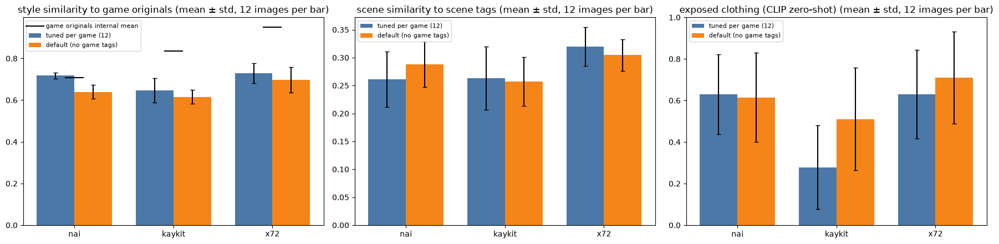

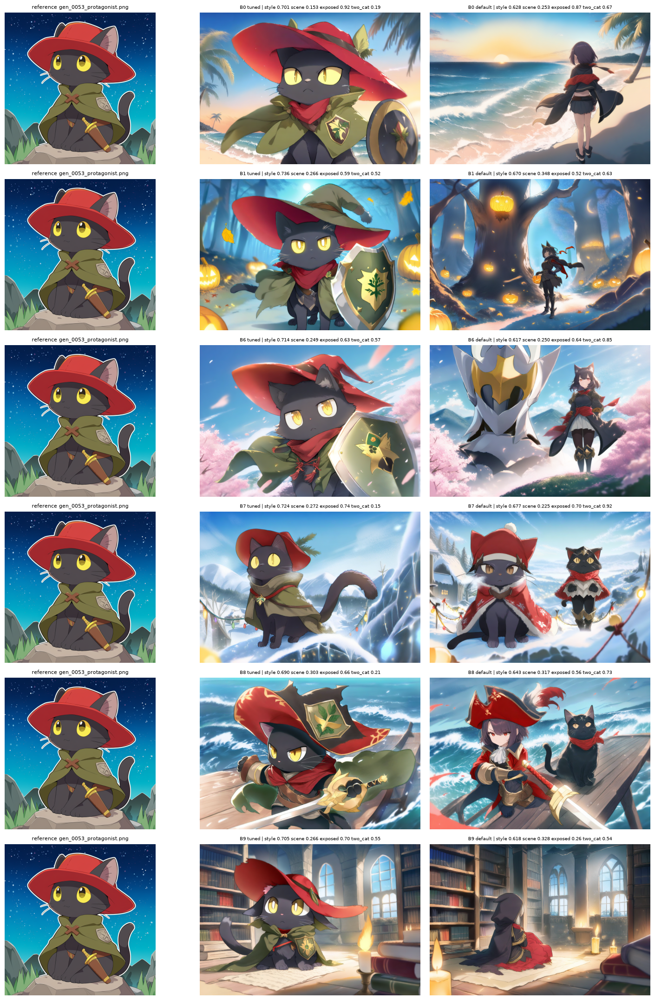

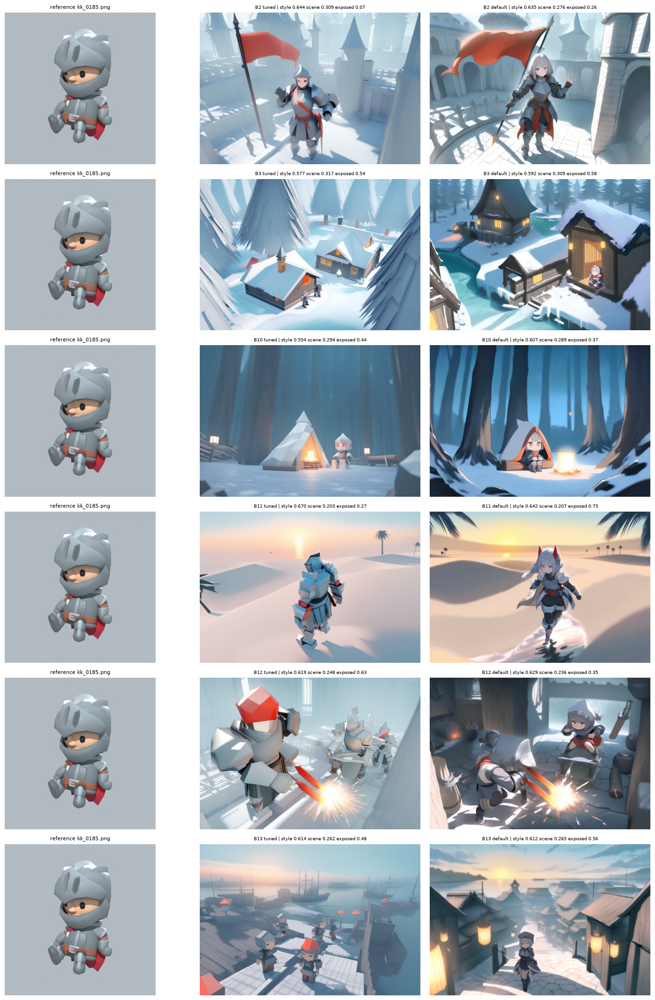

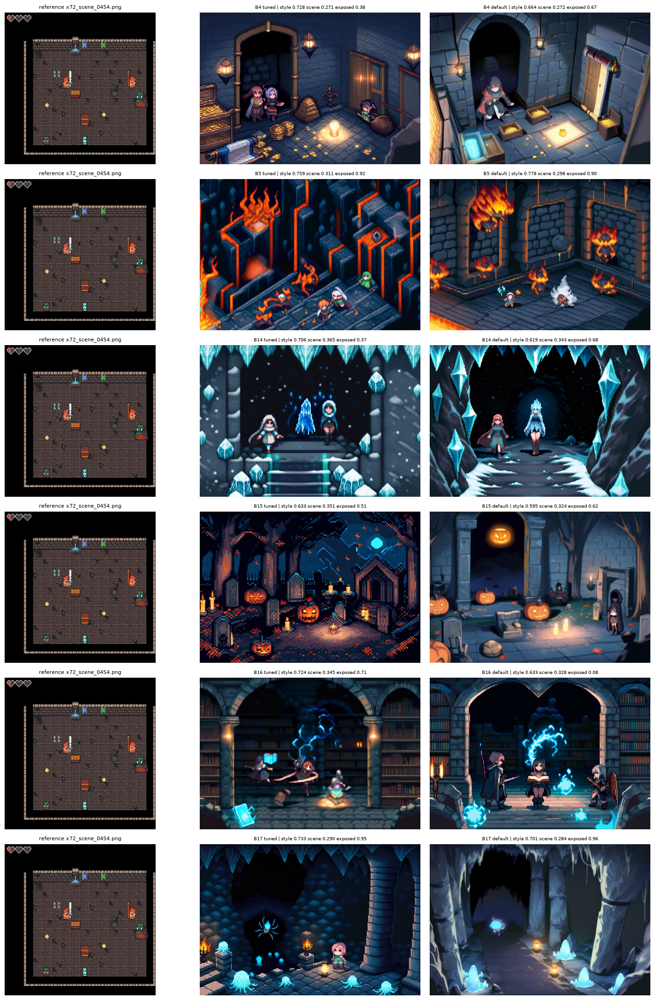

In [4]:
games = ['nai', 'kaykit', 'x72']
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
x = np.arange(len(games))
for k, (cond, color, lab) in enumerate([('tuned', '#4C78A8', 'tuned per game (12)'), ('default', '#F58518', 'default (no game tags)')]):
    for ax, col in zip(axes, ['style_sim', 'scene_sim', 'exposed_prob']):
        v = [cs[(cs.game == g) & (cs.cond == cond)][col] for g in games]
        ax.bar(x + (k - 0.5) * 0.38, [s_.mean() for s_ in v], 0.38, yerr=[s_.std() for s_ in v], capsize=3, color=color, label=lab)
axes[0].scatter(x, [held_base[g] for g in games], color='black', marker='_', s=600, zorder=3, label='game originals internal mean')
for ax, title in zip(axes, ['style similarity to game originals', 'scene similarity to scene tags', 'exposed clothing (CLIP zero-shot)']):
    ax.set_xticks(x, games)
    ax.set_title(f'{title} (mean ± std, 12 images per bar)')
    ax.legend(fontsize=8)
axes[2].set_ylim(0, 1)
plt.tight_layout()
plt.savefig(OUT_DIR / 'cd_scores.png', dpi=90)
plt.show()

# 게임별 그림 (seed 0): 행 = 장면, 열 = 참조 이미지 / 정한 설정 / 기본 설정
for g in games:
    items = list(SCENES[SCENES.game == g]['item'])
    fig, axes = plt.subplots(len(items), 3, figsize=(15, 3.6 * len(items)), squeeze=False)
    for i, it in enumerate(items):
        axes[i, 0].imshow(Image.open(REFS[g]).convert('RGB'))
        axes[i, 0].set_title(f'reference {REFS[g].name}', fontsize=8)
        for j, cond in enumerate(['tuned', 'default']):
            r = cs[(cs['item'] == it) & (cs.seed == 0) & (cs.cond == cond)]
            if len(r):
                r = r.iloc[0]
                axes[i, j + 1].imshow(Image.open(r.path))
                extra = f' two_cat {r.two_cat_prob:.2f}' if g == 'nai' else ''
                axes[i, j + 1].set_title(f"{it} {cond} | style {r.style_sim:.3f} scene {r.scene_sim:.3f} exposed {r.exposed_prob:.2f}{extra}",
                                         fontsize=7)
        for ax in axes[i]:
            ax.axis('off')
    plt.tight_layout()
    plt.savefig(OUT_DIR / f'cd_grid_{g}.png', dpi=50)
    plt.show()

## 결과

| 게임 | 그림체 정한 설정 → 기본 설정 | 장면 정한 설정 → 기본 설정 | 육안 (기본 설정 12장) |
|---|---|---|---|
| 냥기사 | 0.718±0.014 → 0.639±0.033 | 0.261 → 0.288 | 사람 소녀(고양이 귀 포함) 7장, 고양이 3장, 알아볼 수 없음 2장 |
| KayKit | 0.646±0.058 → 0.615±0.033 | 0.263 → 0.257 | 12장 모두 애니풍 인물 |
| 0x72 | 0.729±0.048 → 0.696±0.062 | 0.320 → 0.304 | 2장(B15·B16 seed 1)에 알아볼 수 없는 UI 글자 상자 |

- 출처: "지표" 셀 표(`cd_summary.csv`), 육안은 기본 설정 36장(`CD_*.png`)을 seed 0·1 모두 열어 셌다. "시각화" 셀 그림은 seed 0만 보여 준다.
- 정한 설정 값은 이 노트북에서 다시 잰 값이고 12 기록과 차이가 0이다("지표" 셀 "12 기록과의 최대 차이").
- 그림체 점수는 세 게임 모두 기본 설정이 낮다(−0.031~−0.079). 장면 18건 중 13건에서 기본 설정이 낮다("지표" 셀 장면별 표).
- 냥기사 차이(−0.079)는 두 조건 표준편차(0.014·0.033)보다 크다. KayKit·0x72 차이(−0.031·−0.033)는 표준편차(0.033~0.062) 안이지만, 육안으로 KayKit은 12장 모두 로우폴리 대신 애니풍 인물이 나와 07 "배너 문제 수정 실험"의 KayKit 애니풍 문제가 다시 나타난다.
- 냥기사 기본 설정은 장면 점수가 오르지만(0.261 → 0.288) 주인공이 고양이 기사에서 사람 소녀로 바뀐 장이 7장이다. 캐릭터 태그가 없어 장면 태그만 반영된 것으로 보인다.
- 차이가 가장 작은 장면은 KayKit B2(+0.006)이고, 정한 설정 B2 seed 0도 애니풍 소녀 기사다(`cd_grid_kaykit.png`).
- 노출 확률(`exposed_prob`)은 07에서 사람이 없는 이미지에도 0.92가 나와 지표로 못 쓰는 것을 확인했으므로 해석하지 않는다.
- 생성 시간: 기본 설정 장당 9.5~9.6초(정한 설정 10.2~10.5초), 36장 396.1초, 최대 VRAM 12.99GB(`cd_runs.csv`).

결론: 레퍼런스 아트와 IP-Adapter 0.5만 쓰는 기본 설정은 주인공과 그림체를 유지하지 못한다. 그림체를 유지하려면 게임별로 정한 설정(12)을 써야 한다.